# Las losowy – wprowadzenie

**Plan notatnika:**
1. Idea: wiele drzew zamiast jednego
2. Skąd bierze się „losowość”
3. Jak las przewiduje
4. Pierwszy las losowy – porównanie z pojedynczym drzewem
5. Liczba drzew (`n_estimators`)
6. Ocena bez zbioru testowego – OOB
7. Najważniejsze hiperparametry
8. Ważność cech
9. Las losowy w regresji
10. Zalety i wady
11. Podsumowanie

## 1. Idea: wiele drzew zamiast jednego

W poprzednim rozdziale widzieliśmy, że pojedyncze drzewo łatwo się **przeucza** i jest **niestabilne** – niewielka zmiana danych daje zupełnie inne drzewo (duża wariancja).

**Las losowy (Random Forest)** to zespół (ang. *ensemble*) wielu drzew decyzyjnych. Każde drzewo jest nieco inne i popełnia nieco inne błędy, a ostateczna decyzja to **głosowanie** (klasyfikacja) lub **średnia** (regresja). Błędy pojedynczych drzew w dużej mierze się uśredniają, więc zespół jest dokładniejszy i stabilniejszy niż jedno drzewo. To zasada „mądrości tłumu”.

![Schemat lasu losowego](../obrazki/4.2_las_losowy.png)

Aby uśrednianie miało sens, drzewa muszą być **różne**. Wymuszamy to przez losowość na dwóch poziomach.

## 2. Skąd bierze się „losowość”

1. **Bootstrap (losowanie ze zwracaniem)** – każde drzewo uczy się na własnej próbce danych treningowych o rozmiarze takim jak cały zbiór, wylosowanej **ze zwracaniem**. Niektóre obserwacje powtarzają się, a inne w ogóle nie trafiają do próbki.
2. **Losowy podzbiór cech w każdym podziale** – w każdym węźle drzewo nie rozważa wszystkich cech, tylko **losowy ich podzbiór** (domyślnie $\sqrt{m}$ cech dla klasyfikacji), i z nich wybiera najlepszy podział. Losowanie następuje przy **każdym podziale**, a nie raz dla całego drzewa.

Sprawdźmy, ile różnych obserwacji trafia do jednej próbki bootstrap:

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

rng = np.random.default_rng(40)
n = 100_000

proba_bootstrap = rng.integers(0, n, size=n)          # losowanie n indeksów ze zwracaniem
print(f'Unikalne obserwacje w próbce bootstrap: {len(np.unique(proba_bootstrap)) / n:.1%}')
print(f'Teoretycznie: 1 - 1/e = {1 - np.exp(-1):.1%}')

Unikalne obserwacje w próbce bootstrap: 63.2%
Teoretycznie: 1 - 1/e = 63.2%


In [21]:
rng.integers(0, 100, size=100)

array([86, 30, 92, 59, 59, 62, 53, 50, 38, 45, 25, 37, 45, 33, 30, 84, 30,
       57,  4, 41, 17, 88, 49, 48, 44, 61,  2, 13, 74, 69, 80, 60, 20, 65,
       46, 91, 62, 22, 48, 41,  3, 96, 61, 27, 67, 29, 86,  7, 74,  0, 58,
        0, 71, 11, 98, 70, 75, 55, 64,  4, 12, 69, 88, 71, 99, 89, 51, 53,
       34, 10, 84, 59, 12, 19, 71, 53, 40, 75, 60, 86, 66, 61, 22, 50, 39,
       31, 42, 24, 20, 72, 91, 40, 60, 59, 17, 17, 15, 63, 49, 41])

In [22]:
len(np.unique(rng.integers(0, 100, size=100)))

63

In [3]:
proba_bootstrap

array([ 8925, 77395, 65457, ..., 73526, 88219, 57176], shape=(100000,))

Do każdego drzewa trafia średnio ok. **63%** różnych obserwacji, a pozostałe ok. **37%** to obserwacje „poza próbką” (*out-of-bag*, OOB). Wykorzystamy je w sekcji 6.

## 3. Jak las przewiduje

- **Klasyfikacja:** każde drzewo wskazuje klasę, a las wybiera tę z największą liczbą głosów. W scikit-learn dokładniej: uśrednia **prawdopodobieństwa klas** zwracane przez drzewa (`predict_proba`) i wybiera klasę o najwyższym średnim prawdopodobieństwie.
- **Regresja:** las zwraca **średnią** predykcji drzew.

## 4. Pierwszy las losowy – porównanie z pojedynczym drzewem

Użyjemy sztucznych danych z funkcji `make_classification`: 1500 obserwacji, 10 cech, z czego 5 informatywnych, 2 redundantne (kombinacje informatywnych) i 3 czysty szum. Parametr `shuffle=False` zachowuje kolejność cech, dzięki czemu później łatwo rozpoznamy ich rodzaj. Dodajemy też 5% losowych błędów w etykietach (`flip_y`), jak w prawdziwych, „brudnych” danych.

In [23]:
X_arr, y = make_classification(n_samples=1500, n_features=10, n_informative=5, n_redundant=2,
                               n_repeated=0, flip_y=0.05, class_sep=1.0, shuffle=False, random_state=42)

nazwy_cech = [f'info_{i}' for i in range(5)] + [f'redundantna_{i}' for i in range(2)] + [f'szum_{i}' for i in range(3)]
X = pd.DataFrame(X_arr, columns=nazwy_cech)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Zbiór treningowy:', X_train.shape, '  testowy:', X_test.shape)
X_train.head()

Zbiór treningowy: (1125, 10)   testowy: (375, 10)


,info_0,info_1,info_2,info_3,info_4,redundantna_0,redundantna_1,szum_0,szum_1,szum_2
30,2.682041,0.290366,0.827749,-0.386388,-1.041404,-2.153369,0.306257,1.607854,0.902533,-1.131406
1048,2.171715,2.080918,-1.885312,-0.638166,0.262535,-3.626773,-0.641545,-0.047043,1.454310,0.428821
1017,1.563296,0.166776,-2.255536,-2.185036,-3.455097,-4.031008,3.004179,0.072397,2.518714,1.780625
277,1.850013,0.290352,2.190234,-3.000548,2.695298,2.689012,-3.786566,-1.573497,0.337613,0.675752
1437,0.833724,-0.586512,-0.596413,-1.289316,-1.526772,-1.000634,1.304024,-0.349507,1.026826,-0.262324


In [27]:
pd.Series(y).value_counts()

1    755
0    745
Name: count, dtype: int64

In [36]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
drzewo = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)               # drzewo bez ograniczeń
las = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)  # 100 drzew

wyniki = pd.DataFrame({
    'accuracy trening': [m.score(X_train, y_train) for m in (baseline, drzewo, las)],
    'accuracy test':    [m.score(X_test, y_test) for m in (baseline, drzewo, las)],
}, index=['baseline', 'pojedyncze drzewo', 'las losowy (100 drzew)']).round(3)
wyniki

,accuracy trening,accuracy test
baseline,0.503,0.504
pojedyncze drzewo,1.000,0.797
las losowy (100 drzew),1.000,0.888


Pojedyncze drzewo bez ograniczeń **zapamiętuje dane treningowe** (trafność treningowa 1,0), a na zbiorze testowym wypada wyraźnie gorzej. Las też osiąga 1,0 na treningu (jego drzewa również są głębokie), ale na zbiorze testowym jest **znacznie lepszy** – uśrednienie wielu różnych drzew zmniejszyło wariancję.

Zobaczmy, jak las podejmuje decyzję dla jednej obserwacji. Pojedyncze drzewa są dostępne w atrybucie `estimators_`:

In [38]:
x = X_test.iloc[[0]].to_numpy()                                   # pierwsza obserwacja testowa
glosy = np.array([drzewo_lasu.predict(x)[0] for drzewo_lasu in las.estimators_])

print('Prawdziwa klasa:', y_test[0])
print(f'Głosy drzew: klasa 0 -> {np.sum(glosy == 0)}, klasa 1 -> {np.sum(glosy == 1)}')
print('Predykcja lasu:', las.predict(x)[0])

# predict_proba lasu to średnia z predict_proba drzew
srednia_drzew = np.mean([d.predict_proba(x) for d in las.estimators_], axis=0)
print('Średnie prawdopodobieństwa z drzew:', srednia_drzew.round(3))
print('predict_proba lasu:                ', las.predict_proba(x).round(3))

Prawdziwa klasa: 0
Głosy drzew: klasa 0 -> 57, klasa 1 -> 43
Predykcja lasu: 0
Średnie prawdopodobieństwa z drzew: [[0.57 0.43]]
predict_proba lasu:                 [[0.57 0.43]]


/Users/tomasz/Desktop/ML_DL_szkolenie_23_11_26/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/tomasz/Desktop/ML_DL_szkolenie_23_11_26/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## 5. Liczba drzew (`n_estimators`)

Im więcej drzew, tym stabilniejsza predykcja, ale zysk szybko maleje, a czas obliczeń rośnie liniowo. Sprawdźmy to walidacją krzyżową (5 podziałów) na zbiorze treningowym:

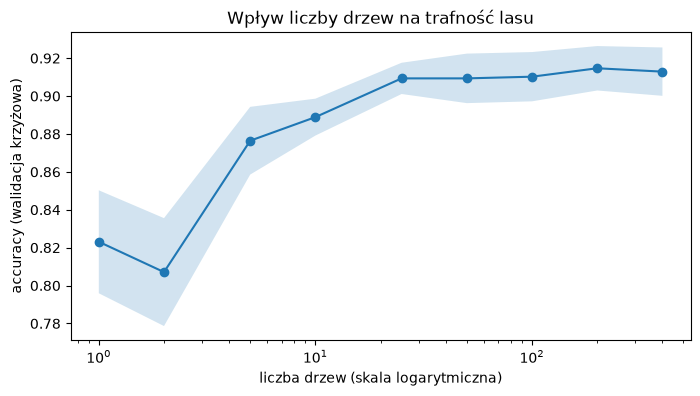

In [39]:
liczby_drzew = [1, 2, 5, 10, 25, 50, 100, 200, 400]
srednie, odchylenia = [], []

for k in liczby_drzew:
    wyniki_cv = cross_val_score(RandomForestClassifier(n_estimators=k, random_state=42),
                                X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    srednie.append(wyniki_cv.mean())
    odchylenia.append(wyniki_cv.std())

srednie, odchylenia = np.array(srednie), np.array(odchylenia)

plt.figure(figsize=(8, 4))
plt.plot(liczby_drzew, srednie, marker='o')
plt.fill_between(liczby_drzew, srednie - odchylenia, srednie + odchylenia, alpha=0.2)
plt.xscale('log')
plt.xlabel('liczba drzew (skala logarytmiczna)')
plt.ylabel('accuracy (walidacja krzyżowa)')
plt.title('Wpływ liczby drzew na trafność lasu')
plt.show()

Wynik szybko rośnie przy pierwszych kilkunastu drzewach, a od ok. 25–50 drzew przestaje się istotnie poprawiać (pasmo wokół linii to odchylenie standardowe z 5 podziałów). Dodawanie kolejnych drzew **nie powoduje przeuczenia** – najwyżej niepotrzebnie wydłuża obliczenia. Zwykle wystarczy 100–500 drzew.

## 6. Ocena bez zbioru testowego – OOB

Każde drzewo nie widziało ok. 37% obserwacji (OOB). Można więc ocenić las, pytając o każdą obserwację **tylko te drzewa, które jej nie widziały podczas uczenia**. Daje to darmowe oszacowanie jakości bez osobnego zbioru walidacyjnego: `oob_score=True`.

In [41]:
las_oob = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42).fit(X_train, y_train)

print(f'OOB score (na danych treningowych): {las_oob.oob_score_:.3f}')
print(f'Accuracy na zbiorze testowym:       {las_oob.score(X_test, y_test):.3f}')

OOB score (na danych treningowych): 0.914
Accuracy na zbiorze testowym:       0.883


Oba wyniki są zbliżone, więc OOB to wiarygodne, tanie oszacowanie jakości (szczególnie przy małych zbiorach danych, gdzie szkoda oddawać obserwacje na zbiór testowy).

## 7. Najważniejsze hiperparametry

| Hiperparametr | Co robi | Uwagi |
|---|---|---|
| `n_estimators` | liczba drzew w lesie | więcej = stabilniej, ale wolniej; domyślnie 100 |
| `max_features` | ile cech losowo rozważa się w każdym podziale | domyślnie `'sqrt'` (klasyfikacja); mniej cech = bardziej różne drzewa |
| `max_depth` | maksymalna głębokość drzew | domyślnie brak limitu |
| `min_samples_split` | minimalna liczba obserwacji w węźle, by go podzielić | większa wartość = prostsze drzewa |
| `min_samples_leaf` | minimalna liczba obserwacji w liściu | większa wartość = gładsze, mniej przeuczone drzewa |
| `bootstrap` | czy losować próbki ze zwracaniem | domyślnie `True` |
| `oob_score` | czy policzyć ocenę OOB | wymaga `bootstrap=True` |
| `class_weight` | wagi klas (np. `'balanced'`, `'balanced_subsample'`) | pomaga przy danych niezbalansowanych |
| `n_jobs` | liczba rdzeni procesora; `-1` = wszystkie | drzewa są niezależne, więc trenowanie łatwo zrównoleglić |
| `random_state` | ziarno losowości | daje powtarzalne wyniki |

Domyślne ustawienia lasu losowego są zwykle dobre, więc jest to model, który „działa od ręki”. Strojenie hiperparametrów (np. `GridSearchCV`) poznamy w rozdziale 4.5.

## 8. Ważność cech

`feature_importances_` mówi, jak bardzo dana cecha pomagała w podziałach. Dla każdego podziału liczymy, o ile zmniejszyła się nieczystość (Gini) w węzłach potomnych, sumujemy te zyski dla każdej cechy po wszystkich drzewach i normalizujemy tak, aby suma ważności wynosiła 1.

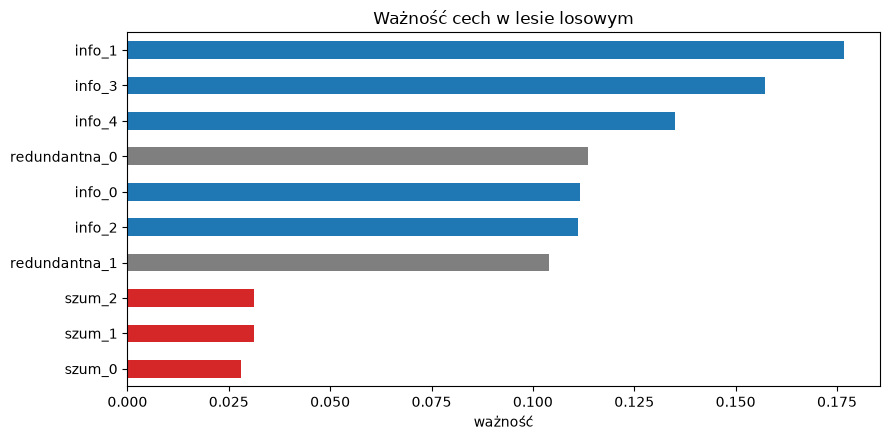

In [43]:
waznosc = pd.Series(las.feature_importances_, index=nazwy_cech).sort_values()
kolory = ['#d62728' if nazwa.startswith('szum') else '#1f77b4' if nazwa.startswith('info') else '#7f7f7f'
          for nazwa in waznosc.index]

waznosc.plot.barh(figsize=(9, 4.5), color=kolory, title='Ważność cech w lesie losowym')
plt.xlabel('ważność')
plt.tight_layout()
plt.show()

Niebieskie słupki (cechy informatywne) mają wysoką ważność, a czerwone (szum) wyraźnie najniższą – las poprawnie odróżnił cechy niosące informację od szumu. Cechy redundantne (szare) są kombinacjami informatywnych, więc niosą tę samą informację i dostają porównywalną ważność.

**Ostrzeżenia dotyczące ważności cech:**
- cechy **silnie skorelowane** dzielą się ważnością (każda z nich wygląda na mniej ważną, niż jest w istocie),
- ważność liczona z podziałów jest **zawyżana dla cech ciągłych i o wielu wartościach**,
- to ważność dla modelu, a nie dowód zależności przyczynowej.

Dokładniejsze metody (m.in. ważność permutacyjna i SHAP) poznamy w rozdziale 4.6 o interpretowalności modeli.

## 9. Las losowy w regresji

`RandomForestRegressor` działa tak samo, ale każde drzewo przewiduje liczbę, a las zwraca **średnią**. Porównajmy go z pojedynczym głębokim drzewem na zaszumionych danych (krzywa sinusa z szumem):

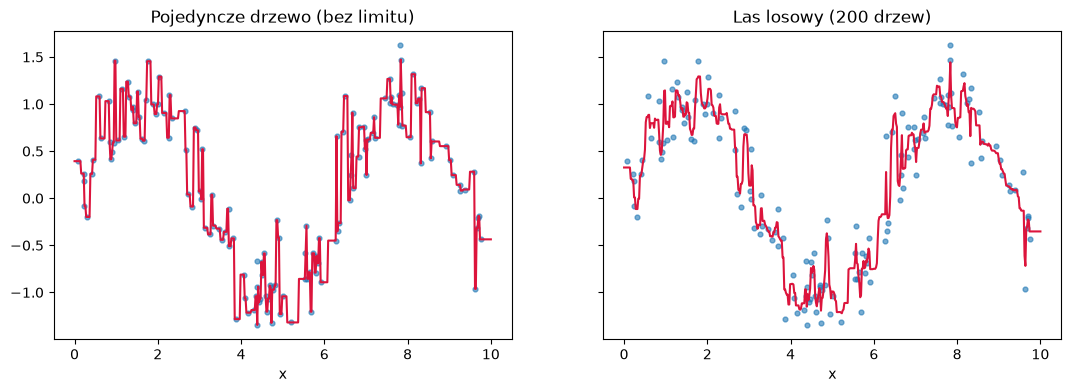

In [44]:
rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 10, 150))
y_reg = np.sin(x) + rng.normal(0, 0.3, size=len(x))
siatka = np.linspace(0, 10, 500).reshape(-1, 1)

drzewo_reg = DecisionTreeRegressor(random_state=42).fit(x.reshape(-1, 1), y_reg)
las_reg = RandomForestRegressor(n_estimators=200, random_state=42).fit(x.reshape(-1, 1), y_reg)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, model, tytul in zip(axes, [drzewo_reg, las_reg], ['Pojedyncze drzewo (bez limitu)', 'Las losowy (200 drzew)']):
    ax.scatter(x, y_reg, s=12, alpha=0.6)
    ax.plot(siatka, model.predict(siatka), color='crimson')
    ax.set_title(tytul)
    ax.set_xlabel('x')
plt.show()

Pojedyncze drzewo dopasowuje się do każdego punktu szumu (poszarpana krzywa), a średnia ze 200 drzew jest **wyraźnie mniej poszarpana** i bliższa prawdziwej zależności. Las nadal tworzy funkcję schodkową i – tak jak drzewo – **nie ekstrapoluje** poza zakres danych.

## 10. Zalety i wady

**Zalety:**
- **Wysoka dokładność** przy niewielkim strojeniu – często dobry model „od ręki”.
- **Znacznie mniej podatny na przeuczenie** niż pojedyncze drzewo (uśrednianie zmniejsza wariancję), a dodawanie drzew nie pogarsza wyniku.
- **Nie wymaga skalowania cech**, radzi sobie z zależnościami nieliniowymi i interakcjami.
- **Odporny na szum i obserwacje odstające** w cechach.
- Daje **ważność cech** i darmową ocenę **OOB**.
- Działa zarówno w klasyfikacji, jak i regresji; łatwo go **zrównoleglić** (`n_jobs=-1`).

**Wady:**
- **Trudniejszy do interpretacji** niż pojedyncze drzewo – nie da się narysować prostych reguł (setki drzew).
- **Większe zużycie pamięci i dłuższy czas** trenowania oraz predykcji niż jedno drzewo.
- **Nie ekstrapoluje** poza zakres danych treningowych.
- Przy bardzo dużej liczbie cech i rzadkich danych (np. tekst) bywa gorszy od modeli liniowych.
- Nadal może się przeuczyć na bardzo zaszumionych danych – hiperparametry (`min_samples_leaf`, `max_depth`) warto stroić.

## 11. Podsumowanie

1. Las losowy to zespół wielu drzew uczonych na **różnych próbkach bootstrap** i z **losowym podzbiorem cech w każdym podziale**.
2. Predykcja to **głosowanie** (klasyfikacja) lub **średnia** (regresja).
3. Uśrednianie różnych drzew **zmniejsza wariancję**: las jest dokładniejszy i stabilniejszy niż pojedyncze drzewo.
4. Więcej drzew nie powoduje przeuczenia; wynik stabilizuje się po kilkudziesięciu–kilkuset drzewach.
5. `oob_score=True` daje ocenę jakości bez osobnego zbioru walidacyjnego.
6. `feature_importances_` pokazuje, które cechy były ważne, ale trzeba pamiętać o ich ograniczeniach.

W kolejnym notatniku porównamy pojedyncze drzewo i las losowy na danych o odejściach klientów (Churn).